# Wall & Floor Segmentation for Interior Photographs
**Nirwana AI · AI Engineer take-home**  ·  [Open in Colab](https://colab.research.google.com/github/shlokdhanokar/nirwana-wall-floor-segmentation/blob/main/notebooks/Wall_Floor_Segmentation.ipynb)

Given an interior photo, produce pixel-level **wall** and **floor** masks.

**Runtime → Run all** works on a fresh Colab runtime (CPU is enough; GPU is used if present).
Jump to **§3** to upload your own image.

**TL;DR**
* **Formulation:** 3-class dense labelling *(other / wall / floor)* rather than two independent binary problems. Wall and floor are mutually exclusive, and the hard negatives (ceiling, windows, doors, furniture) need a class of their own.
* **Model:** *WallFloorNet*, a 3.3 M-parameter encoder-decoder (MobileNetV3 encoder plus my own global-context FPN decoder), **trained by me** on ~9.2k interior scenes filtered from ADE20K. No pre-trained or fine-tuned *segmentation* model is used anywhere (see §0).
* **Post-processing:** the probabilities are upsampled to full resolution and decided by argmax, then connected-component cleanup removes specks and pinholes. A guided-filter edge-snapping stage was built, tested in an 11-setting sweep, and **switched off** because it did not improve boundaries (§4).
* **Baseline / first experiment:** a training-free geometric pipeline (LSD vanishing-point horizon plus GrabCut), kept for comparison. It handles floors reasonably and walls poorly. That result is the reason a learned model was needed.
* **Speed:** about 0.25 s end-to-end for a full-resolution 3558×2160 photo on 2 CPU threads (ONNX Runtime, FP32), down from ~1.3 s for the first working version. INT8 quantisation was tried and rejected (§6).

Best checkpoint: epoch 28, ADE20K-interior val IoU wall **0.735**, floor **0.815**.


## 0 · Constraint compliance & disclosures
| Constraint | How it is met |
|---|---|
| No pre-trained / fine-tuned **segmentation** model | No segmentation weights of any kind are loaded. The full segmentation network (decoder, head, loss, training loop) is defined in `wallfloor/model.py` and `wallfloor/train.py` and was trained from scratch for this task. |
| Segmentation logic developed in this solution | The label space and ADE20K remapping, the interior-scene filter, the architecture, augmentations, losses, guided-filter refinement, cleanup and the classical baseline are all written for this project. |
| No segmentation API / cloud service | Everything runs locally in this notebook (PyTorch or ONNX Runtime on CPU/GPU). |
| Disclose external models / data / libraries / AI tools | **Encoder initialisation:** torchvision's MobileNetV3-Large **ImageNet-1k classification** weights (an image classifier, not a segmenter). `--no-pretrained-encoder` trains it from random init instead. **Dataset:** ADE20K SceneParsing (MIT CSAIL), used for its *wall*, *floor* and *rug* labels only. **Libraries:** PyTorch, torchvision, OpenCV, NumPy, ONNX / ONNX Runtime, Matplotlib. **AI tools:** Claude Code (Anthropic) was used as a coding assistant. |


In [1]:
# --- setup: get the code + trained weights (works on a fresh Colab runtime and locally) ---
import os, sys, subprocess, importlib
REPO_URL = "https://github.com/shlokdhanokar/nirwana-wall-floor-segmentation"
if os.path.isdir("wallfloor"):
    ROOT = os.getcwd()
elif os.path.isdir("../wallfloor"):
    ROOT = os.path.abspath("..")
else:
    if not os.path.isdir("repo"):
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "repo"], check=True)
    ROOT = os.path.abspath("repo")
os.chdir(ROOT); sys.path.insert(0, ROOT)
if importlib.util.find_spec("onnxruntime") is None:   # the only dependency Colab lacks
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "onnxruntime"], check=True)

import cv2, numpy as np, torch, matplotlib.pyplot as plt, json, time
from wallfloor.infer import WallFloorSegmenter, load_rgb
from wallfloor.classical import segment_classical
from wallfloor.metrics import binary_iou, boundary_f1
from wallfloor.viz import show, overlay, save_outputs
print("torch", torch.__version__, "| CUDA:", torch.cuda.is_available())
print(sorted(os.listdir("weights")))

torch 2.13.0+cpu | CUDA: False
['.gitkeep', 'wallfloor_mbv3.onnx', 'wallfloor_mbv3.pt', 'wallfloor_mbv3_history.json', 'wallfloor_mbv3_int8.onnx']


## 1 · Problem formulation
* **Input:** one RGB interior photo of any size and aspect ratio. **Output:** two binary masks at the *input* resolution.
* **Label definitions** (the main ambiguity in the task):
  * *Wall*: vertical room surfaces, including paint, wallpaper, tile and stone cladding. Windows, doors, curtains, pictures and furniture in front of the wall are **not** wall.
  * *Floor*: walkable ground surface. A **rug or carpet counts as floor**, matching the reference GT supplied with the task. Furniture legs and objects on the floor are **not** floor.
  * Everything else (ceiling, windows, furniture, people, plants, ...) is *other*.
* **Why 3 classes and not 2 binary problems:** the masks must not overlap, and the softmax forces the network to explain the confusers (ceiling vs. wall, glossy floor vs. reflection, window vs. bright wall) explicitly.
* **Why learning:** wall and floor are defined by **3-D layout and semantics**, not appearance. A white wall, white ceiling and white floor can share the same colour, and a striped rug can look like wooden planks. Appearance-only rules break on that (see §5, experiment 1), so the system has to learn layout priors from data.


## 2 · Pipeline
```
image (any size) ─► resize (short side 384, /32) ─► WallFloorNet ─► softmax probs (≈384 px)
   ─► bilinear upsample to output res (≤2048 px) ─► argmax ─► CC cleanup ─► nearest upsample ─► wall, floor masks
      (optional, off by default: flip-TTA; guided-filter refinement with the full-res image as guide)
```
**WallFloorNet** (`wallfloor/model.py`)
* *Encoder*: MobileNetV3-Large feature extractor, taps at strides 4/8/16/32. Chosen for its accuracy per FLOP on CPU.
* *Context block* (stride 32): wall vs. floor is mostly a **global layout** decision. A pixel of beige texture is floor at the bottom of the room and wall behind the sofa. The block gates a local projection with a global-average-pooled descriptor (LR-ASPP style) and concatenates an explicit global context vector.
* *Top-down FPN*: fuses stride 16 → 8 → 4 with lateral 1×1 convs and depthwise-separable 3×3 smoothing, which keeps boundaries (skirting lines, wall corners) sharp at low cost.
* *Loss*: cross-entropy (`ignore_index` for unannotated pixels, mild class weights) **plus soft Dice** on wall and floor, so large easy regions don't dominate.
* *Training data*: ADE20K filtered to **interior scenes** with a label-statistics heuristic (`wallfloor/labels.py::is_interior`: no sky, some wall/floor, ceiling or floor present). That leaves 9.2k train and 922 val images. Labels are remapped `wall→1, floor|rug→2, other→0, unlabelled→ignore`.
* *Augmentation*: scale 0.6–1.6, crops, ±8° rotation (handheld photos), **horizontal flip only** (a vertical flip would break the floor-is-down prior the model should learn), strong colour, exposure, blur and noise jitter (walls come in every colour, and interiors range from tungsten-dim to blown-out daylight).


## 3 · Run on an image
The reference image shipped with the assignment, scored against its ground-truth masks:

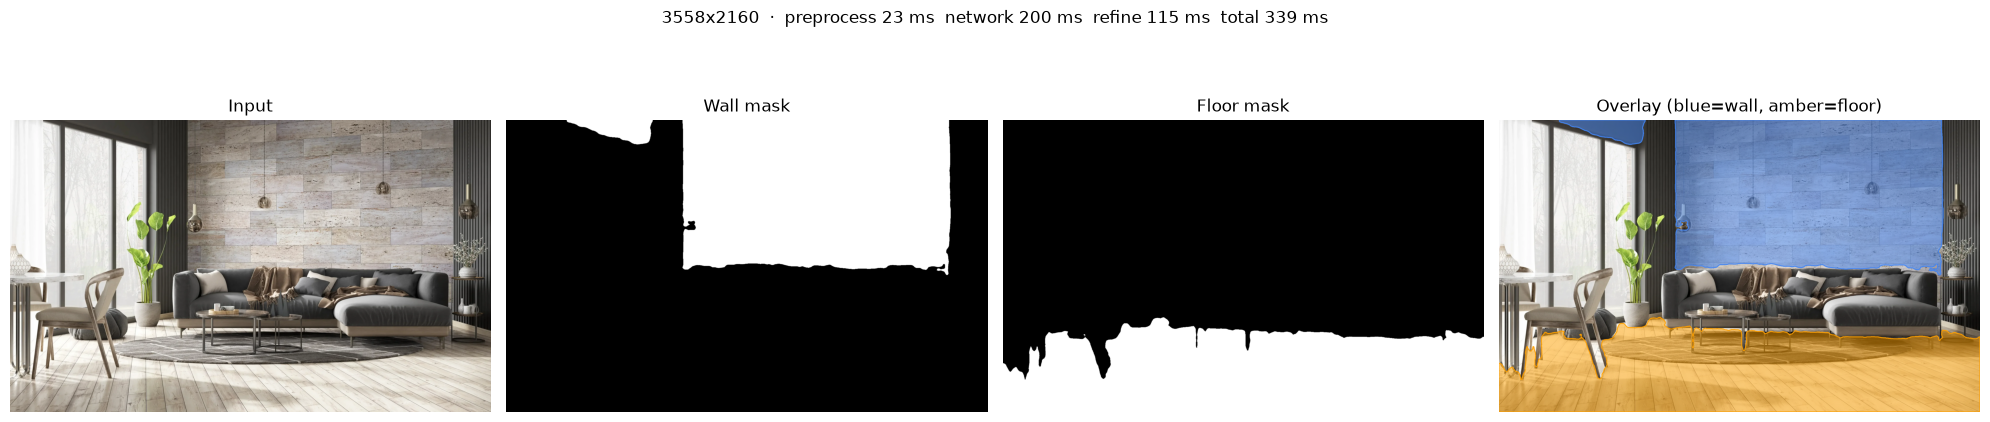

wall   IoU = 0.930   boundary-F = 0.577


floor  IoU = 0.946   boundary-F = 0.767


In [2]:
seg = WallFloorSegmenter("weights/wallfloor_mbv3.pt", short_side=384)   # defaults: no TTA, no guided refinement

img = load_rgb("samples/Contemporary_Stone_Accent_Lounge.webp")
out = seg(img)
show(img, out, title=f"{img.shape[1]}x{img.shape[0]}  ·  " +
     "  ".join(f"{k} {v*1000:.0f} ms" for k, v in out["timings"].items()))

gt = {k: cv2.imread(f"samples/gt/Contemporary_Stone_Accent_Lounge_{k}.png", 0) > 127 for k in ("wall", "floor")}
for k in ("wall", "floor"):
    print(f"{k:5s}  IoU = {binary_iou(out[k], gt[k]):.3f}   boundary-F = {boundary_f1(out[k], gt[k]):.3f}")
save_outputs(img, out, "results/samples", "Contemporary_Stone_Accent_Lounge")   # full-res masks as PNG

**Reading the score on this image:** the reference GT labels only the **stone accent wall** as wall. The dark vertical slat panelling at both sides, the windows and the pendant lamps are excluded. The model gives the same answer (wall IoU ≈ 0.93, floor IoU ≈ 0.95). The remaining errors are a small leak of the wall mask into the top of the window at the left edge of the stone wall, and the thin chair and table legs on the floor, which are a few pixels wide even at full resolution.

### Try your own image
On Colab, run the next cell and pick a file (or set `IMAGE_URL`). Any interior photo works, at any resolution.

No upload - using the bundled sample image.


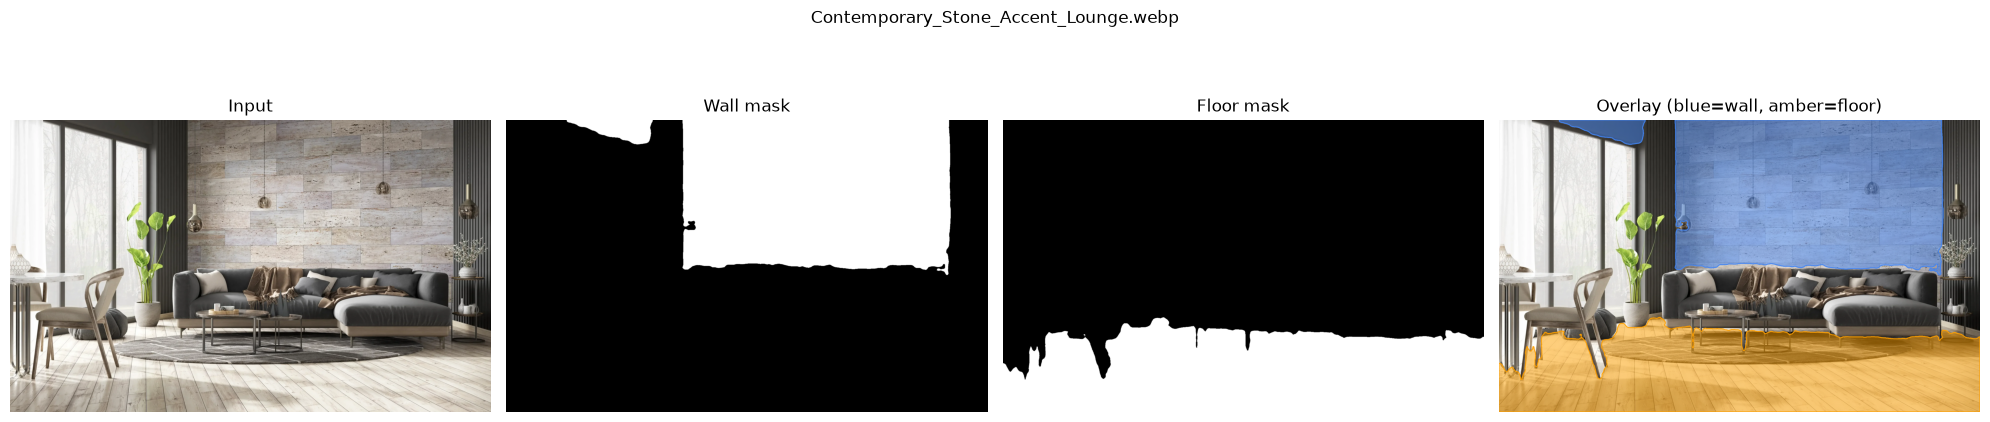

masks saved to results/uploads/


In [3]:
IMAGE_URL = ""   # optionally paste a direct image URL here
paths = []
try:
    from google.colab import files            # Colab upload widget
    up = files.upload()
    paths = list(up.keys())
except Exception:
    pass
if IMAGE_URL:
    import urllib.request
    urllib.request.urlretrieve(IMAGE_URL, "url_image.jpg"); paths.append("url_image.jpg")
if not paths:
    print("No upload - using the bundled sample image.")
    paths = ["samples/Contemporary_Stone_Accent_Lounge.webp"]
for p in paths:
    im = load_rgb(p)
    o = seg(im)
    show(im, o, title=os.path.basename(p))
    save_outputs(im, o, "results/uploads", os.path.splitext(os.path.basename(p))[0])
print("masks saved to results/uploads/")

## 4 · What each stage contributes, and an experiment that didn't pan out
The network outputs probabilities at ~384 px. **Hypothesis:** snapping them to full-resolution image edges with a fast guided filter (He & Sun 2015) should sharpen the mask boundaries. It was implemented efficiently (`wallfloor/refine.py`: the argmax decision functions are linear in the guide, so only per-pixel coefficients are upsampled) and then **measured**. An 11-setting sweep over radius, eps and working resolution on 200 validation images plus the reference image ([`results/refine_sweep.md`](../results/refine_sweep.md)) found **no setting that beats plain bilinear upsampling on boundary F**. The radius that adds +0.004 IoU on the reference image costs −0.07 floor boundary-F there. The grayscale guide pulls edges toward strong *texture* edges (plank seams, stone veins, rug patterns), not toward surface boundaries. So refinement is off by default. The crops below show both:

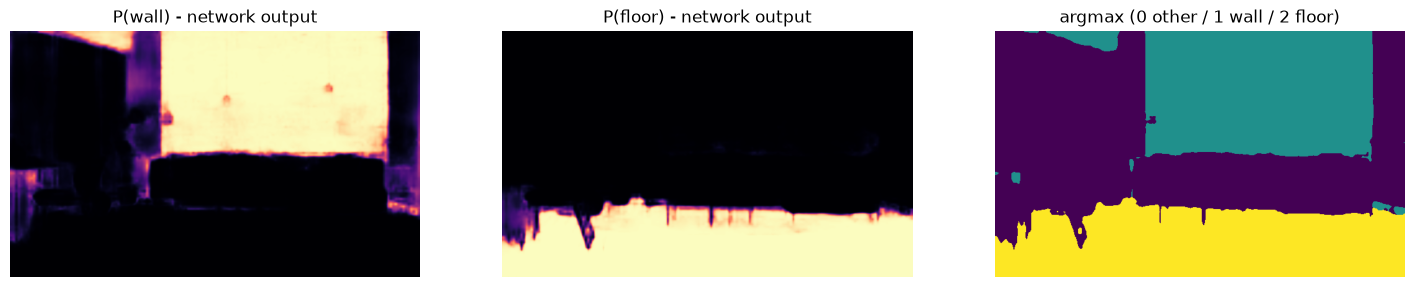

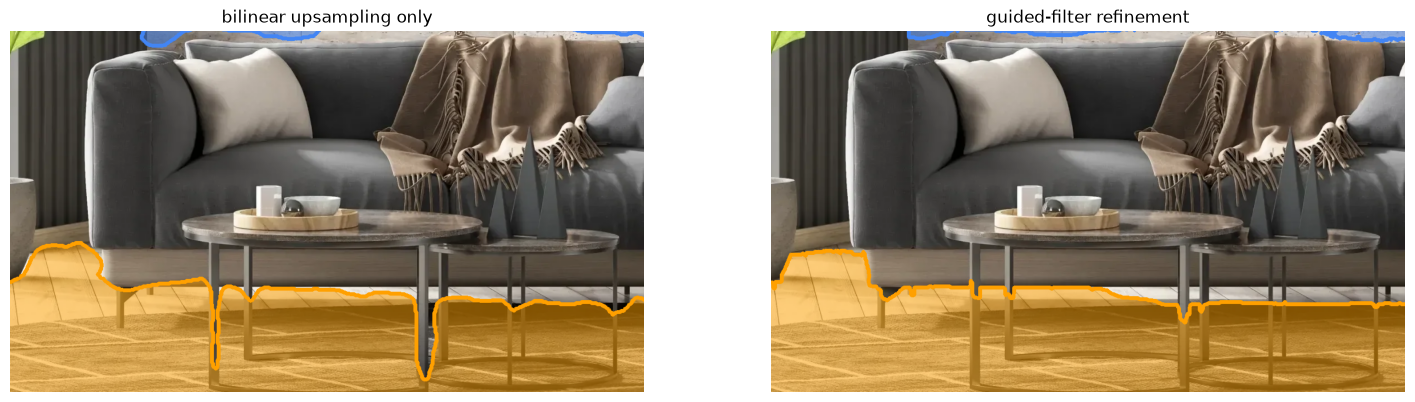

raw      floor IoU 0.946  BF 0.767 | wall IoU 0.930  BF 0.577


refined  floor IoU 0.950  BF 0.699 | wall IoU 0.934  BF 0.591


In [4]:
raw = WallFloorSegmenter("weights/wallfloor_mbv3.pt", tta=False, refine=False)(img)
ref = WallFloorSegmenter("weights/wallfloor_mbv3.pt", tta=False, refine=True)(img)
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
ax[0].imshow(out["probs"][..., 1], cmap="magma"); ax[0].set_title("P(wall) - network output")
ax[1].imshow(out["probs"][..., 2], cmap="magma"); ax[1].set_title("P(floor) - network output")
ax[2].imshow(out["probs"].argmax(2), cmap="viridis"); ax[2].set_title("argmax (0 other / 1 wall / 2 floor)")
[a.axis("off") for a in ax]; plt.show()

H, W = img.shape[:2]
y0, y1, x0, x1 = int(.50*H), int(.80*H), int(.30*W), int(.62*W)    # sofa / coffee-table / rug region
fig, ax = plt.subplots(1, 2, figsize=(18, 6))
for a, (o, t) in zip(ax, [(raw, "bilinear upsampling only"), (ref, "guided-filter refinement")]):
    a.imshow(overlay(img, o["wall"], o["floor"])[y0:y1, x0:x1]); a.set_title(t); a.axis("off")
plt.show()
for name, o in [("raw", raw), ("refined", ref)]:
    print(f"{name:8s} floor IoU {binary_iou(o['floor'], gt['floor']):.3f}  BF {boundary_f1(o['floor'], gt['floor']):.3f} | "
          f"wall IoU {binary_iou(o['wall'], gt['wall']):.3f}  BF {boundary_f1(o['wall'], gt['wall']):.3f}")

## 5 · Experiments & iteration
**Experiment 1: training-free geometric baseline** (`wallfloor/classical.py`). This came first, to see how far image-formation priors alone go:
1. LSD line segments → pairwise intersections of oblique segments → weighted-median **horizon** (Manhattan-world vanishing geometry).
2. **GrabCut** seeded with *floor below the horizon* / *definite floor in a bottom-centre band*, then a second GrabCut for *wall between ceiling band and horizon*.

It gets the floor of the reference image largely right but leaks wall into the bright window and curtains. That is expected: GrabCut's colour GMMs cannot tell a white wall from a white window or ceiling. Walls are defined by geometry and semantics, not by colour. It is also slow (~seconds per image) because of the iterative graph cuts. This failure is what motivated a learned model.

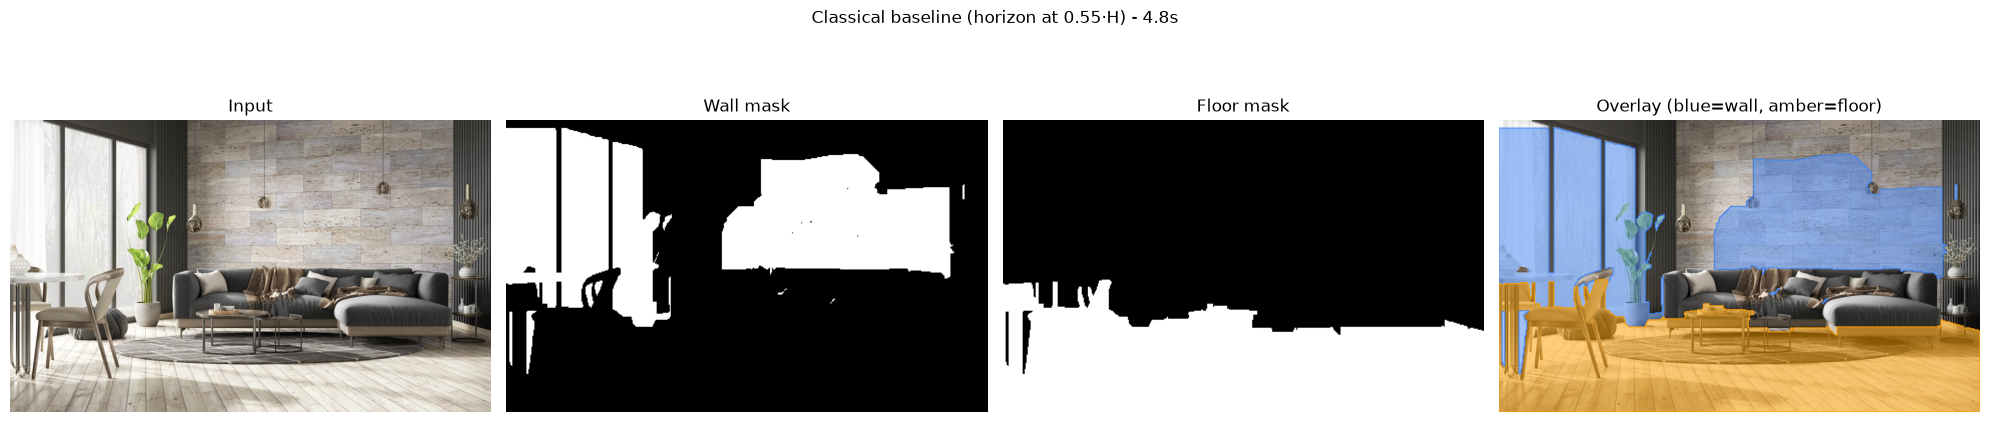

classical wall  IoU 0.334   vs  WallFloorNet 0.930
classical floor IoU 0.793   vs  WallFloorNet 0.946


In [5]:
t0 = time.perf_counter(); cl = segment_classical(img); t_cl = time.perf_counter() - t0
show(img, cl, title=f"Classical baseline (horizon at {cl['horizon']:.2f}·H) - {t_cl:.1f}s")
for k in ("wall", "floor"):
    print(f"classical {k:5s} IoU {binary_iou(cl[k], gt[k]):.3f}   vs  WallFloorNet {binary_iou(out[k], gt[k]):.3f}")

**Experiments 2–6: learned model, refinement, TTA, resolution, quantisation.** Quantitative comparison on the
held-out **ADE20K interior validation split** (922 images, never trained on) and on the reference image.
IoU is per-class over the whole split. BF is the boundary F-score at a tolerance of 0.75 % of the image diagonal, so it measures edge quality, which IoU barely reflects.
Latency is end-to-end on the 3558×2160 reference photo (AMD Ryzen 5 4600H laptop CPU, 2 threads, median of 10 runs), *including* resize and post-processing.

| Variant | val IoU wall | val IoU floor | val mIoU | val BF wall | val BF floor | sample IoU wall | sample IoU floor | latency (ms) |
|---|---|---|---|---|---|---|---|---|
| classical (LSD horizon + GrabCut) | 0.384 | 0.324 | 0.354 | 0.433 | 0.407 | 0.321 | 0.793 | 4976 |
| net 384 (default) | 0.751 | 0.839 | 0.795 | 0.696 | 0.764 | 0.930 | 0.946 | 317 |
| net 384 + guided-filter refine | 0.749 | 0.837 | 0.793 | 0.684 | 0.750 | 0.934 | 0.950 | 478 |
| net 384 + flip-TTA | 0.753 | 0.842 | 0.797 | 0.699 | 0.769 | 0.906 | 0.945 | 537 |
| ONNX fp32 384 (default) | 0.751 | 0.839 | 0.795 | 0.696 | 0.764 | 0.930 | 0.946 | 256 |
| ONNX int8 384 | 0.686 | 0.797 | 0.741 | 0.640 | 0.726 | 0.914 | 0.928 | 247 |
| ONNX fp32 256 | 0.729 | 0.809 | 0.769 | 0.658 | 0.727 | 0.919 | 0.878 | 173 |
| ONNX fp32 320 | 0.744 | 0.832 | 0.788 | 0.684 | 0.755 | 0.909 | 0.926 | 223 |
| ONNX fp32 448 | 0.748 | 0.835 | 0.792 | 0.696 | 0.764 | 0.913 | 0.947 | 260 |

**What the table says**
* **Learning was the right call:** val mIoU 0.354 → 0.795, with walls going from 0.38 to 0.75 IoU. The classical baseline is also ~19× slower.
* **Guided refinement does not earn its place.** On the 12 MP reference photo it nudges IoU up (wall 0.931 → 0.934, floor 0.946 → 0.950) but lowers floor boundary-F (0.767 → 0.699). On validation it lowers both IoU and BF slightly. It also costs ~0.15 s. Off by default (sweep in §4).
* **Flip-TTA isn't worth it:** +0.002 val mIoU, but it drops the reference wall IoU from 0.930 to 0.906 and costs 1.7× latency, so it is off by default.
* **Input resolution:** 384 px is the sweet spot. 320 px costs 0.007 mIoU for −13 % latency; 256 px costs 0.026. 448 px adds nothing, since the receptive field then covers less of the room.
* **INT8 post-training quantisation: rejected** (−5.4 mIoU for a 4 % speed-up; see §6).
* The in-training validation number (0.775 at epoch 28) is lower than the 0.793–0.795 here because training-time validation scores the raw network output at 384 px. This table runs the full pipeline (cleanup included) at the stored image resolution.


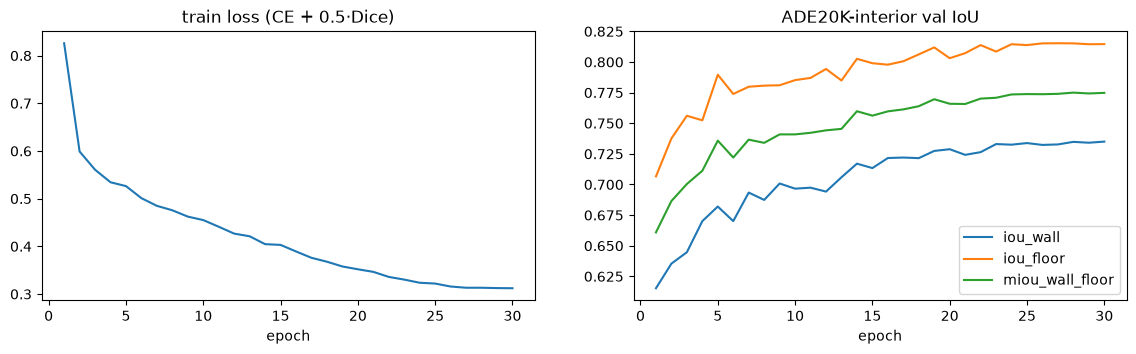

,variant,val_iou_wall,val_iou_floor,val_miou,val_bf_wall,val_bf_floor,val_images,sample_iou_wall,sample_bf_wall,sample_iou_floor,sample_bf_floor,latency_ms_3558x2160_cpu
0,classical (LSD horizon + GrabCut),0.384,0.324,0.354,0.433,0.407,150,0.321,0.305,0.793,0.260,4975.676
1,net 384 (default),0.751,0.839,0.795,0.696,0.764,922,0.930,0.577,0.946,0.767,317.233
2,net 384 + guided-filter refine,0.749,0.837,0.793,0.684,0.750,922,0.934,0.591,0.950,0.699,477.953
3,net 384 + flip-TTA,0.753,0.842,0.797,0.699,0.769,922,0.906,0.526,0.945,0.760,536.661
4,ONNX fp32 384 (default),0.751,0.839,0.795,0.696,0.764,922,0.930,0.577,0.946,0.767,255.687
5,ONNX int8 384,0.686,0.797,0.741,0.640,0.726,922,0.914,0.528,0.928,0.709,247.070
6,ONNX fp32 256,0.729,0.809,0.769,0.658,0.727,922,0.919,0.493,0.878,0.600,173.220
7,ONNX fp32 320,0.744,0.832,0.788,0.684,0.755,922,0.909,0.484,0.926,0.740,223.245
8,ONNX fp32 448,0.748,0.835,0.792,0.696,0.764,922,0.913,0.538,0.947,0.797,260.267


In [6]:
import pandas as pd
hist = pd.DataFrame(json.load(open("weights/wallfloor_mbv3_history.json")))
fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
ax[0].plot(hist.epoch, hist.loss); ax[0].set_title("train loss (CE + 0.5·Dice)"); ax[0].set_xlabel("epoch")
for c in ("iou_wall", "iou_floor", "miou_wall_floor"):
    ax[1].plot(hist.epoch, hist[c], label=c)
ax[1].legend(); ax[1].set_title("ADE20K-interior val IoU"); ax[1].set_xlabel("epoch"); plt.show()
pd.DataFrame(json.load(open("results/metrics.json"))).round(3)

Held-out validation images, **worst / median / best** by per-image mIoU (prediction row, then ground-truth row). The failure cases matter as much as the successes:

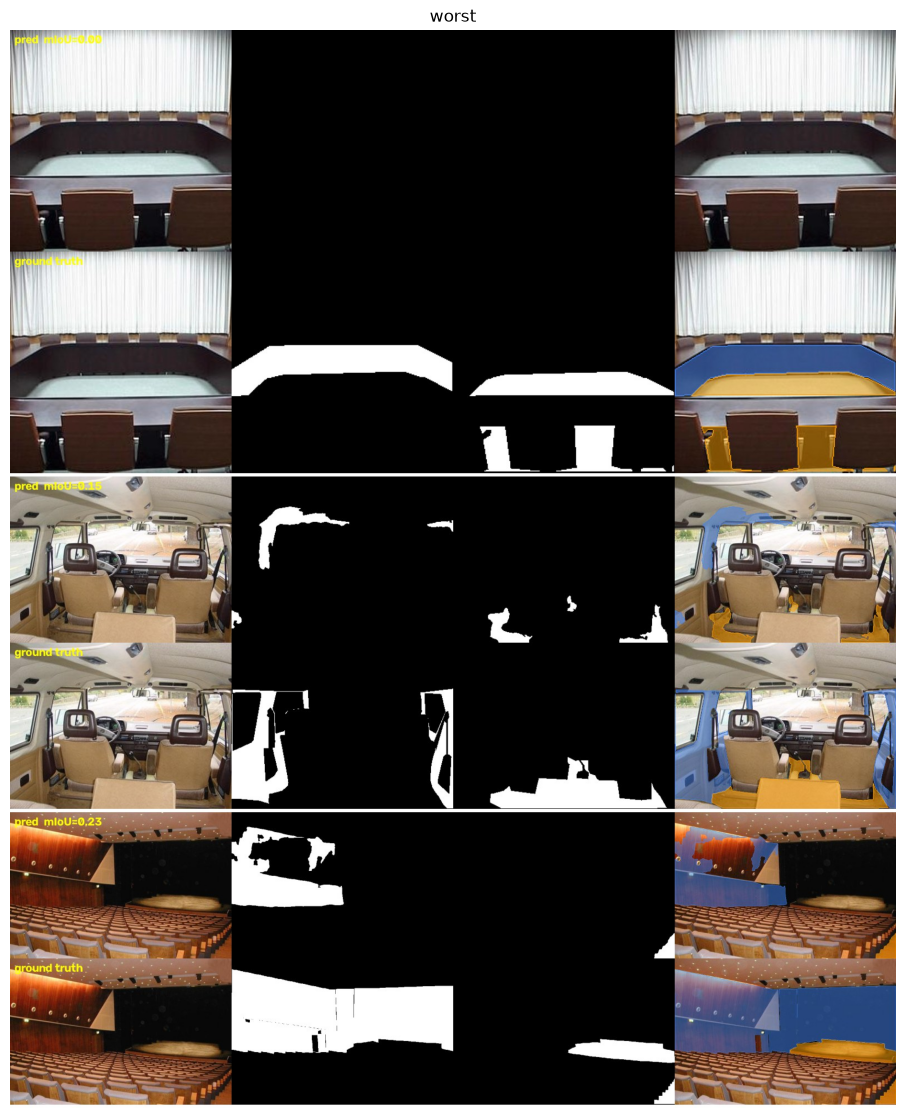

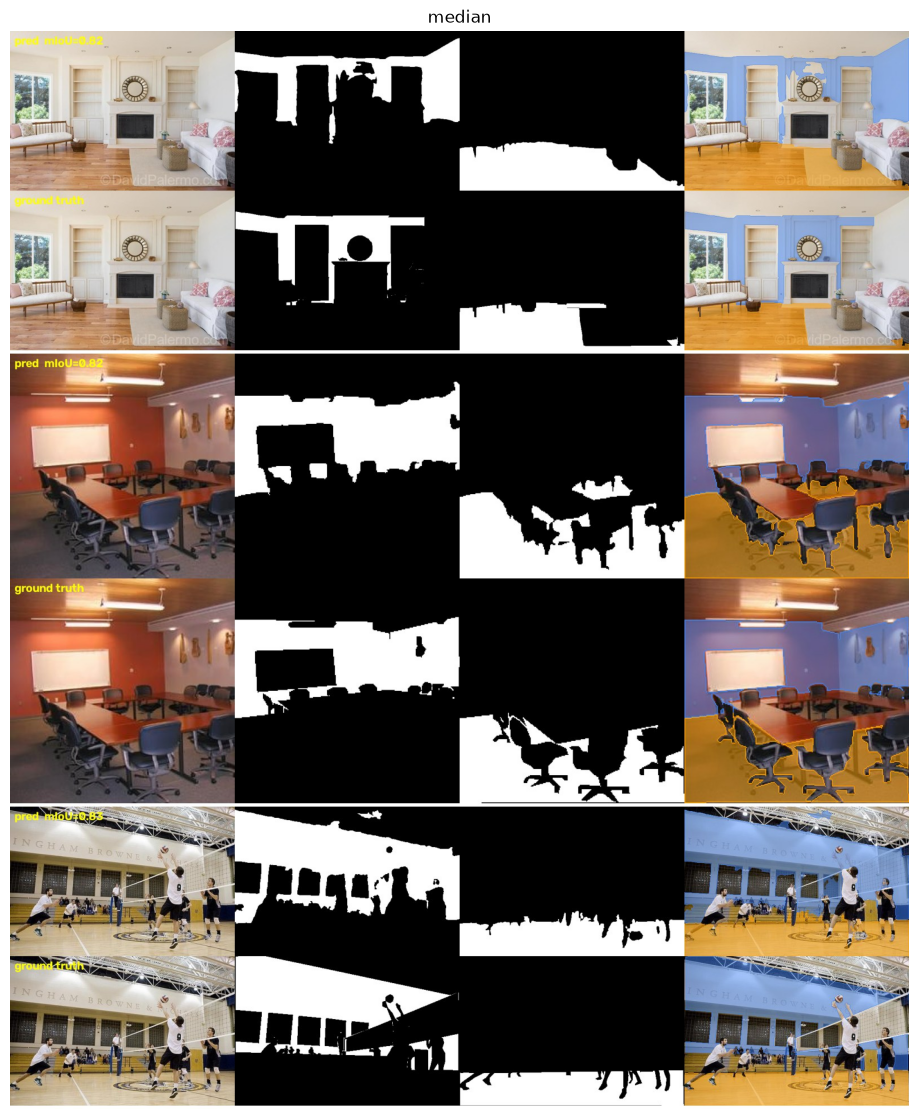

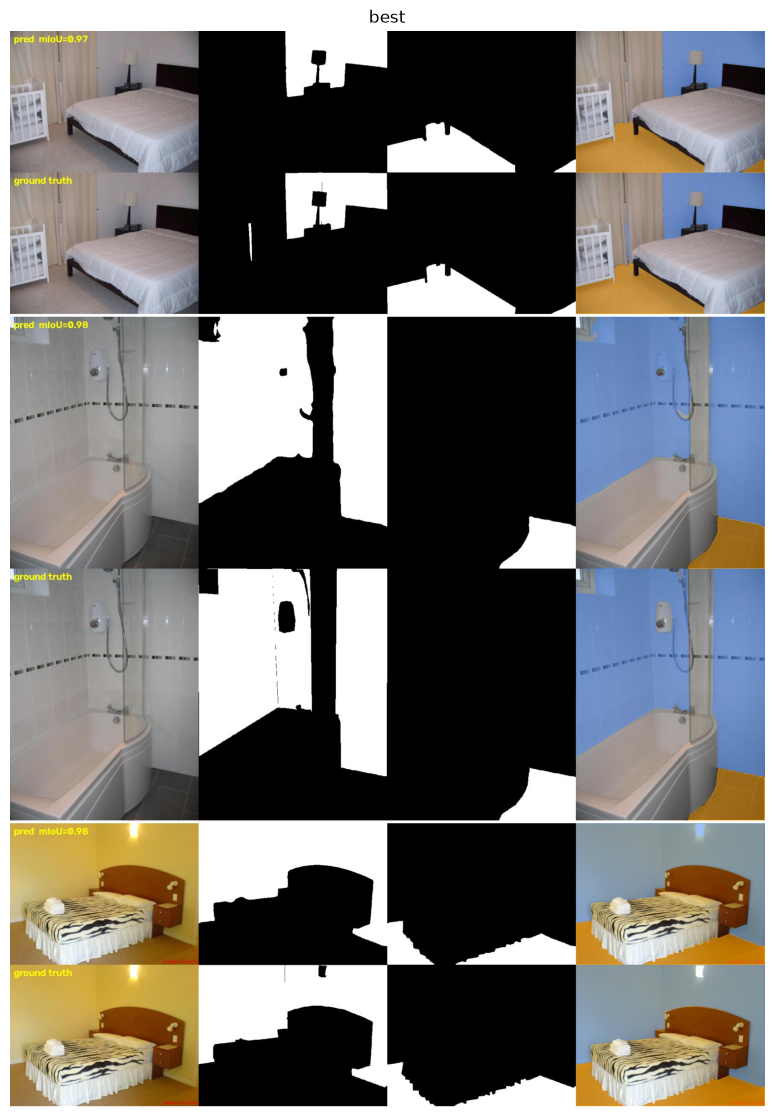

In [7]:
for tag in ("worst", "median", "best"):
    p = f"results/gallery/val_{tag}.jpg"
    if os.path.exists(p):
        plt.figure(figsize=(18, 14)); plt.imshow(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB))
        plt.title(tag); plt.axis("off"); plt.show()

## 6 · Performance optimisation (bonus)
Levers, in order of impact:
1. **Architecture budget:** MobileNetV3 plus a 0.34 M-parameter decoder: 3.3 M params in total, 13 MB FP32.
2. **Decouple network resolution from output resolution:** the network sees ~384 px. Running it at full 3558×2160 would be roughly 50× more compute and *less* accurate, because the receptive field would cover a smaller share of the room. The argmax is evaluated as three linear decision functions (q_w−q_f, 2q_w+q_f−1, 2q_f+q_w−1), so full resolution only sees single-channel resize and compare ops. Decisions are capped at 2048 px and the final uint8 label map is nearest-upsampled (≤1.7 px edge error on 12 MP).
3. **Full-resolution post-processing rewritten** from numpy passes over float probability maps to fused OpenCV uint8 ops. Connected-component cleanup runs on a conservative max-pooled copy. 12 MP post-processing went from ~0.9 s to ~0.1 s.
4. **ONNX Runtime** graph optimisations (operator fusion) for the CPU path.
5. **INT8 static quantisation, tried and rejected.** QDQ with per-channel weights and percentile calibration gives a 3.5× smaller file (13.3 → 3.8 MB), but it costs **5.4 mIoU points** on validation and only cuts end-to-end latency by 4 % (256 → 247 ms), because the network is only part of the end-to-end time. Min/max calibration was worse (−6 to −8 points). MobileNetV3's hard-swish and squeeze-excite activations are known to be quantisation-sensitive. Quantisation-aware training would be the way to recover the accuracy if model size mattered (e.g. on-device).
6. **Flip-TTA, measured and switched off.** +0.002 val mIoU, a worse reference wall (0.930 → 0.906), and 1.7× latency.

Live benchmark on *this* runtime:

In [8]:
def bench(s, im, n=5):
    s(im); ts = []
    for _ in range(n):
        t0 = time.perf_counter(); s(im); ts.append(time.perf_counter() - t0)
    return 1000 * float(np.median(ts))

threads = os.cpu_count()
cfgs = [("PyTorch FP32 CPU, TTA", WallFloorSegmenter("weights/wallfloor_mbv3.pt", tta=True, device="cpu", threads=threads)),
        ("PyTorch FP32 CPU",      WallFloorSegmenter("weights/wallfloor_mbv3.pt", tta=False, device="cpu", threads=threads)),
        ("ONNX FP32 CPU",         WallFloorSegmenter("weights/wallfloor_mbv3.onnx", tta=False, threads=threads)),
        ("ONNX INT8 CPU",         WallFloorSegmenter("weights/wallfloor_mbv3_int8.onnx", tta=False, threads=threads))]
if torch.cuda.is_available():
    cfgs.append(("PyTorch GPU (AMP), TTA", WallFloorSegmenter("weights/wallfloor_mbv3.pt", tta=True, device="cuda")))
rows = []
for name, s in cfgs:
    o = s(img)
    rows.append({"config": name, "latency_ms (3558x2160)": round(bench(s, img)),
                 "IoU wall": round(binary_iou(o["wall"], gt["wall"]), 3), "IoU floor": round(binary_iou(o["floor"], gt["floor"]), 3)})
for f in ("wallfloor_mbv3.pt", "wallfloor_mbv3.onnx", "wallfloor_mbv3_int8.onnx"):
    print(f"{f:28s} {os.path.getsize('weights/' + f)/1e6:5.1f} MB")
pd.DataFrame(rows)

wallfloor_mbv3.pt             13.5 MB
wallfloor_mbv3.onnx           13.3 MB
wallfloor_mbv3_int8.onnx       3.8 MB


,config,latency_ms (3558x2160),IoU wall,IoU floor
0,"PyTorch FP32 CPU, TTA",464,0.906,0.945
1,PyTorch FP32 CPU,290,0.930,0.946
2,ONNX FP32 CPU,218,0.930,0.946
3,ONNX INT8 CPU,232,0.914,0.928


## 7 · Reproduce training (optional, ~1 h on a Colab T4)
Set `RUN_TRAINING = True` to download ADE20K (~1 GB), rebuild the interior subset and retrain from scratch. The trained weights in `weights/` were produced by exactly this code.

In [9]:
RUN_TRAINING = False
if RUN_TRAINING:
    if not os.path.isdir("data/ADEChallengeData2016"):
        os.makedirs("data", exist_ok=True)
        subprocess.run(["wget", "-q", "-O", "data/ade.zip",
                        "http://data.csail.mit.edu/places/ADEchallenge/ADEChallengeData2016.zip"], check=True)
        subprocess.run(["unzip", "-q", "data/ade.zip", "-d", "data"], check=True)
    subprocess.run([sys.executable, "-m", "wallfloor.prepare", "--ade-root", "data/ADEChallengeData2016",
                    "--out", "data/cache", "--workers", "2"], check=True)
    subprocess.run([sys.executable, "-m", "wallfloor.train", "--cache", "data/cache", "--out", "weights/retrained.pt",
                    "--epochs", "40", "--batch", "16", "--workers", "2"], check=True)
    subprocess.run([sys.executable, "-m", "wallfloor.export", "--weights", "weights/retrained.pt"], check=True)

## 8 · Technical discussion

### Why this approach, and what it assumes about interior images
* **Wall and floor are layout concepts, not appearance concepts.** The same beige texture is floor at the bottom of the frame and wall behind the sofa, and a white wall, white ceiling and white window can be colour-identical. A method that decides pixel-by-pixel from colour and texture is capped well below what's needed. The classical baseline reaches 0.38 wall IoU on held-out interiors, against 0.75 for the learned model. The model has to reason about **where a surface sits in the room**. That is why the decoder has an explicit global-context path, and why the network runs at a moderate resolution (384 px) where its receptive field covers the whole room. Going to 448 px did not help.
* **A learned model, trained by me, under the "no pre-trained segmentation model" rule.** The useful knowledge (rooms have a floor at the bottom, walls meet it at a skirting line, rugs lie on floors, windows sit in walls) is easiest to acquire from labelled interiors. ADE20K provides wall/floor/rug labels for ~9k interiors. The segmentation network was designed and trained from scratch for this task. Only the encoder starts from generic ImageNet-classification features, and that is disclosed and switchable.
* **Classical CV where it measurably helps:** connected-component cleanup (cheap, deterministic, removes specks and pinholes) and the classical baseline as a yardstick. Guided-filter edge snapping was built and **rejected on evidence** (below).
* **Assumptions:**
  1. The photo is an interior taken roughly upright (±~10° roll; the model sees ±8° rotations in training).
  2. "Floor" includes rugs and carpets and excludes objects standing on it.
  3. "Wall" means wall surfaces and excludes openings (windows, doors) and objects hung on it.
  4. Typical perspective photography. Fisheye or 360° panoramas are out of distribution.

### Hardest cases and how they were handled
| Case | Why it is hard | Handling / status |
|---|---|---|
| White wall vs. white ceiling vs. bright window | Same colour, no texture | Global-context block plus training data where ceilings and windows are explicit *other*. GrabCut failed exactly here (wall leaked into the window: 0.32 IoU on the reference image vs. 0.93 learned) |
| Floor vs. rug vs. wood-look panelling | Rugs have strong patterns; plank textures appear on walls too | Rug merged into floor in the label map, matching the provided GT. Layout context separates floor planks from wall planks |
| Accent wall vs. side panelling | Is dark slat panelling "wall"? The reference GT says no | The model agrees with the GT on the reference image (wall IoU 0.93). In general this is a *convention* question to fix with the product team and encode in the labels |
| Thin structures (chair and table legs) | A few pixels wide even at full resolution, sub-pixel at 384 px | Cleanup fills only holes < 0.05 % of the image, so furniture holes are preserved. Guided filtering did *not* improve these boundaries (sweep below) |
| Out-of-scope "interiors" | The label-statistics interior filter lets through vehicle cabins and multi-storey atria | Visible in the worst-case gallery. A scene classifier or scene-category filter would clean the training/val data |
| Noisy / inconsistent ground truth | Some ADE20K annotations disagree with the task's convention | Visible in the worst-case gallery. It caps measured IoU; the fix is in-domain relabelling |
| Arbitrary resolutions / aspect ratios | A 3558×2160 input would be expensive and shift the receptive field | Network runs on short side 384 (aspect preserved, /32). Decisions are made at ≤ 2048 px and nearest-upsampled |

### Experiments that changed the design (all measured, see §5)
* **Classical → learned:** val mIoU 0.354 → 0.795, and ~19× faster.
* **Guided-filter refinement: hypothesis rejected.** An 11-setting sweep (`results/refine_sweep.md`) found no radius/eps that beats plain bilinear upsampling on boundary F. The grayscale guide snaps to texture edges (plank seams, stone veins) as readily as to surface boundaries. It is off by default.
* **Flip-TTA: not worth it.** +0.002 val mIoU, a worse reference wall (0.930 → 0.906), 1.7× latency. Off by default.
* **Input resolution:** 384 px is the knee of the curve (320: −0.007 mIoU, 256: −0.026, 448: no gain).
* **INT8 post-training quantisation: rejected.** −5.4 mIoU (percentile calibration; min/max is worse) for only a 4 % latency reduction.

### Alternatives considered
1. **Purely classical** (vanishing points + GrabCut / superpixel region growing). Implemented as the baseline: no data needed and explainable, but it fails on colour-ambiguous scenes and is slower. Kept as evidence for the decision.
2. **Room-layout estimation** (fit a cuboid room, e.g. LayoutNet/HorizonNet-style corner and edge regression), then subtract objects. It gives very clean planar walls, but it needs layout-annotated data, assumes a cuboid and still needs a separate clutter mask. A good second stage, though.
3. **Monocular depth + surface normals → plane fitting** (floor = large horizontal plane at the bottom, walls = vertical planes). It would need a pre-trained depth network. That isn't a segmentation model, but it is a grey area under the rules and a heavy dependency, so it was not used.
4. **Self-supervised features (DINOv2/CLIP) + a small trained head.** Probably the most accurate per hour of work, but it means a large backbone, it's slower on CPU, and it's closer to "using a foundation segmenter" than I wanted.
5. **From-scratch encoder** (no ImageNet init). Supported by `--no-pretrained-encoder` but **not run** within the time budget. With 9k training images I'd expect slower convergence and lower accuracy. It is the obvious next ablation for a strict reading of the rules.

### How mask quality was evaluated
* **Held-out quantitative:** per-class IoU and mIoU over the 922-image ADE20K interior *validation* split. It is never trained on and is used only to pick the best epoch.
* **Boundary F-score** (tolerance 0.75 % of the diagonal), because IoU is dominated by large interior regions and barely moves when edges are off by 10 px. Edge quality is what a re-texturing product actually shows the user. This metric is what exposed that guided refinement was not helping, even though it nudged IoU up on the reference image.
* **Reference image** supplied with the task: IoU/BF against its GT masks.
* **Qualitative stratified review:** worst / median / best validation images by per-image mIoU, so failure modes are inspected rather than cherry-picked successes.
* **Every pipeline change is an ablation row** (refinement, TTA, input resolution, FP32 vs INT8) with quality *and* latency, so trade-offs are explicit.

### What I would do next for real-world robustness
1. **Data:** collect and label a few thousand in-domain photos (real-estate listings, phone photos, renders like the reference image) under the *product's* wall/floor convention. Add hard-negative mining of mirrors, glass partitions, glossy floors, open-plan spaces and empty rooms. Label noise and convention mismatch currently cost more than model capacity.
2. **Geometry-aware second stage:** fit planes or a room layout to the predicted wall/floor regions, regularise each wall to a planar polygon, and enforce wall–floor adjacency at a single skirting line. That gives crisp, product-grade boundaries (where the guided filter failed) and lets one wall be separated from another (useful for per-wall re-texturing).
3. **Better edge refinement:** a guide that encodes *surface identity* rather than intensity, i.e. the network's own stride-4 features, or a dense CRF / learned refinement head trained on boundary bands.
4. **Instance-level walls** (each wall plane separately), plus an explicit *ceiling* class.
5. **Uncertainty output:** expose per-pixel confidence (the softmax margin is already computed) so the product can ask the user to confirm low-confidence regions instead of failing silently.
6. **Compression done properly:** quantisation-aware training if the model must ship on-device, and a TensorRT / CoreML build for edge deployment.

### Limitations (honest summary)
* Learned priors come from ADE20K's annotation conventions, which won't always match a product's definition of "wall".
* No explicit 3-D reasoning, so mirrors and reflections can be labelled as the surface they reflect.
* Very unusual viewpoints (top-down atria, strong roll, fisheye) and scenes with little visible floor are weaker.
* A single "wall" mask merges all wall planes. Separate wall instances would need the next steps above.
* The from-scratch-encoder ablation was not run, so how much the ImageNet initialisation contributes is not quantified.
